Code for A bspline curve s(x) that maps from parameteric space $x \in R$ to $s \in R$:\

$s(x)=\sum_i P_i N_{i,p}(x)$




In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np



class bsplines:

    def __init__(self, degree, n_basis, nodal_values):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        # Clamped knot vector is for interpolatory ends
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        self.nodal_values = nodal_values
    def forward(self,x):

        def bspline_basis(i, p, x, knots):
            if p == 0:
                return ((x >= knots[i]) & (x < knots[i+1])).float()
            else:
                denom1 = knots[i+p] - knots[i]
                denom2 = knots[i+p+1] - knots[i+1]

                term1 = 0.0
                if denom1 > 0:
                    term1 = (x - knots[i]) / denom1 * bspline_basis(i, p-1, x, knots)

                term2 = 0.0
                if denom2 > 0:
                    term2 = (knots[i+p+1] - x) / denom2 * bspline_basis(i+1, p-1, x, knots)

                return term1 + term2
        
        y = torch.zeros(self.n_basis, x.shape[0])
        for i in range(self.n_basis):
            y[i] = bspline_basis(i, self.degree, x, self.knot_vector)
                
        bspline = self.nodal_values@y

        return bspline, y

Implementation in Yau et al., CAD 38 (2006) 1123–1133

In [2]:
def cox_de_boor(x, control_points, knot_vector, report=False):
    p = 2
    knots = knot_vector

    # Find span
    if x == 1:
        r = len(knots) - p - 2
    else:
        r = torch.where((knots[:-1] <= x) & (x < knots[1:]))[0].item()

    # Active control points P_{r-p},...,P_r
    P_prev = control_points[r-p : r+1].clone()
    

    if report:
        print('knot_vector', knots)
        print('Control points (P)', control_points)
        print('r=', r)
        print(f'P^{0}= ', P_prev[:,1])

    # Cox–de Boor recursion
    for j in range(1, p+1):
        P = torch.zeros((p-j+1, control_points.shape[1]))
        alfa = torch.zeros((p-j+1))

        for i in range(0, p-j+1):
            left_index  = r - p + i
            right_index = r + i + 1    # <-- FIXED HERE

            denom = knots[right_index] - knots[left_index]
            alpha = 0.0 if denom == 0 else (x - knots[left_index]) / denom
            alfa[i] = alpha

            P[i] = (1 - alpha) * P_prev[i] + alpha * P_prev[i+1]
            # P[i] = (1 - alpha) * P_prev[i+1] + alpha * P_prev[i]

        P_prev = P

        if report:
            print('alpha=', alfa)
            print(f'P^{j}= ', P[:,1])

    return P_prev[0]


In [10]:
knots =torch.tensor([0.0, 0.0, 0.0, 0.5, 1.0, 1.0, 1.0])
x = torch.tensor(1)
torch.where((knots[:-1] < x) & (x <= knots[1:]))[0].item()


3

In [16]:
x_vals = torch.linspace(0,0.99999,1000)
knots = model.knot_vector
r_list = []
p = 2

for x in x_vals:
        print(x)
        if x == 1:
            r = len(knots) - p - 2

        if x==0:
             r = 2
        else:
            r = torch.where((knots[:-1] <= x) & (x <= knots[1:]))[0].item()
        r_list.append(r)
        

tensor(0.)
tensor(0.0010)
tensor(0.0020)
tensor(0.0030)
tensor(0.0040)
tensor(0.0050)
tensor(0.0060)
tensor(0.0070)
tensor(0.0080)
tensor(0.0090)
tensor(0.0100)
tensor(0.0110)
tensor(0.0120)
tensor(0.0130)
tensor(0.0140)
tensor(0.0150)
tensor(0.0160)
tensor(0.0170)
tensor(0.0180)
tensor(0.0190)
tensor(0.0200)
tensor(0.0210)
tensor(0.0220)
tensor(0.0230)
tensor(0.0240)
tensor(0.0250)
tensor(0.0260)
tensor(0.0270)
tensor(0.0280)
tensor(0.0290)
tensor(0.0300)
tensor(0.0310)
tensor(0.0320)
tensor(0.0330)
tensor(0.0340)
tensor(0.0350)
tensor(0.0360)
tensor(0.0370)
tensor(0.0380)
tensor(0.0390)
tensor(0.0400)
tensor(0.0410)
tensor(0.0420)
tensor(0.0430)
tensor(0.0440)
tensor(0.0450)
tensor(0.0460)
tensor(0.0470)
tensor(0.0480)
tensor(0.0490)
tensor(0.0500)
tensor(0.0511)
tensor(0.0521)
tensor(0.0531)
tensor(0.0541)
tensor(0.0551)
tensor(0.0561)
tensor(0.0571)
tensor(0.0581)
tensor(0.0591)
tensor(0.0601)
tensor(0.0611)
tensor(0.0621)
tensor(0.0631)
tensor(0.0641)
tensor(0.0651)
tensor(0.0661)

In [2]:
def cox_de_boor_vector(x_vals, control_points, knot_vector, report=False):
    
    p = 2
    knots = knot_vector
    N = len(x_vals)

    r_list = []

    for x in x_vals:
        if x == 1:
            r = len(knots) - p - 2
        if x==0:
             r = 2
        else:
            r = torch.where((knots[:-1] < x) & (x <= knots[1:]))[0].item()
        r_list.append(r)

    r_list = torch.tensor(r_list, dtype=torch.long)  # shape (N,)

    P_prev = []

    for r in r_list:
        P_prev.append(control_points[r-p : r+1].clone())

    # shape becomes (N, p+1, 2)
    P_prev = torch.stack(P_prev, dim=0)

    if report:
        print("Initial P_prev:")
        print(P_prev[:,:,1])

    # ------------------------------------------------------------
    # 3) Cox–de Boor recursion (same structure as original!)
    # ------------------------------------------------------------
    for j in range(1, p+1):

        new_count = p - j + 1  # number of new points at this recursion level
        P = torch.zeros((N, new_count, control_points.shape[1]))
        
        for i in range(new_count):
            left_index  = r_list - p + i
            right_index = r_list + i + 1

            # Compute alpha for each x
            left_knots  = knots[left_index]
            right_knots = knots[right_index]

            denom = right_knots - left_knots
            denom[denom == 0] = 1e-12

            alpha = (x_vals - left_knots) / denom   # vector of length N

            P[:, i, :] = (1 - alpha).unsqueeze(1) * P_prev[:, i, :] + \
                         alpha.unsqueeze(1) * P_prev[:, i+1, :]

        P_prev = P  

        if report:
            print(f"P^{j}:")
            print(P[:,:,1])

    # Return shape (N,2), as in your original: the last P_prev[*,0]
    return P_prev[:, 0, :]




In [74]:
control_points = torch.tensor([
    [0.0, 0.0],
    [0.3333, 0.5],
    [0.666666, 0.5],
    [1.0, 0.0]
])

x = torch.tensor(0.6)
knot_vector = torch.tensor([0.0, 0.0, 0.0, 0.5, 1.0, 1.0, 1.0])
P = cox_de_boor(x, control_points, knot_vector, report=True)
print('y_cox= ', P[1].item())


knot_vector tensor([0.0000, 0.0000, 0.0000, 0.5000, 1.0000, 1.0000, 1.0000])
Control points (P) tensor([[0.0000, 0.0000],
        [0.3333, 0.5000],
        [0.6667, 0.5000],
        [1.0000, 0.0000]])
r= 3
P^0=  tensor([0.5000, 0.5000, 0.0000])
alpha= tensor([0.6000, 0.6000])
P^1=  tensor([0.3000, 0.5000])
alpha= tensor([0.6000])
P^2=  tensor([0.4200])
y_cox=  0.42000001668930054


Run the models and plot comparison

nodal_values P: tensor([0.8823, 0.9150, 0.3829, 0.9593, 0.3904, 0.6009, 0.2566, 0.7936, 0.9408,
        0.1332, 0.9346, 0.5936, 0.8694, 0.5677, 0.7411, 0.4294, 0.8854, 0.5739,
        0.2666, 0.6274])


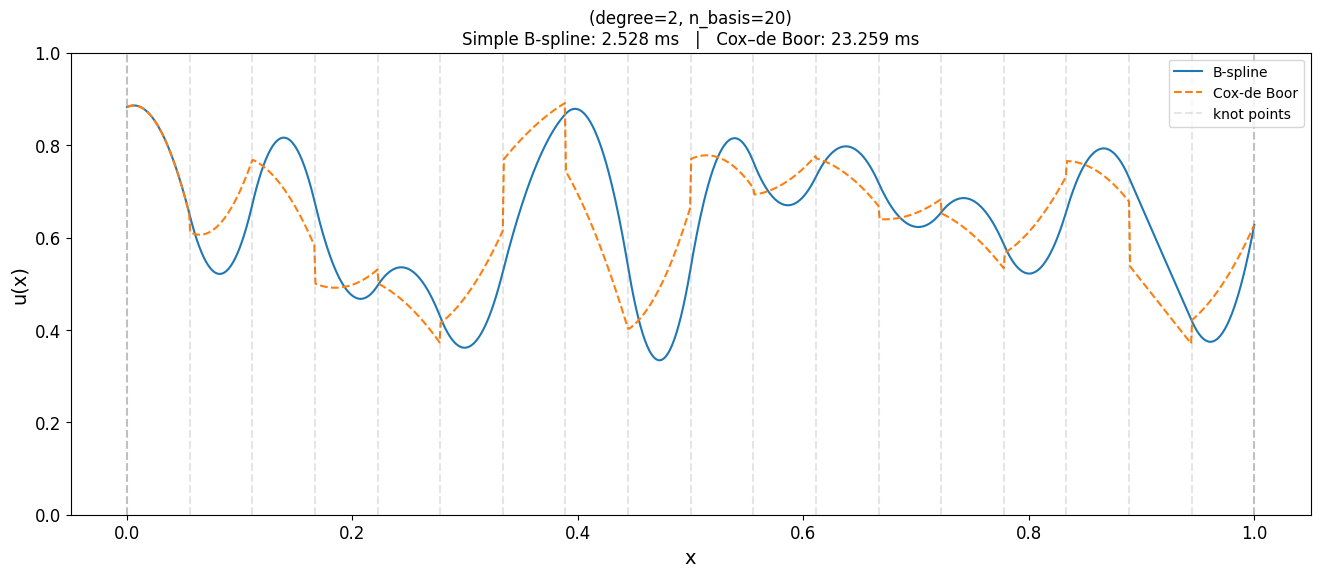

In [3]:
import time
import torch
torch.manual_seed(42)

degree, n_basis = 2, 20

nodal_values = torch.rand(n_basis)
# nodal_values[0] = 0.0
# nodal_values[-1] = 0.0
print('nodal_values P:', nodal_values)
x_coords = torch.linspace(0.0, 1.0, len(nodal_values))
control_points = torch.stack([x_coords, nodal_values], dim=1)
x = torch.linspace(0,0.99999,1000)



model = bsplines(degree, n_basis, nodal_values)

# Simple B_spline
t0 = time.perf_counter()
y_pred, y = model.forward(x)
knot_points = model.knot_vector.detach().numpy()
time_simple = time.perf_counter() - t0   





# Implementation in Yau et al., CAD 38 (2006) 1123–1133
t2 = time.perf_counter()
y_cox = cox_de_boor_vector(x, control_points, model.knot_vector)
time_cox = time.perf_counter() - t2




# Plotting
plt.figure(figsize=(16,6))
plt.plot(x,y_pred, label='B-spline')
# idx = 2
# plt.plot(x, y[idx, :], label=fr"$N_{{{idx},2}}$")
plt.plot(x,y_cox[:,1], '--', label='Cox-de Boor')
plt.vlines(knot_points, ymax=1, ymin=0, color='gray', linestyle='--', label="knot points", alpha=0.2)
plt.legend()
plt.xlabel("x",fontsize=14)
plt.ylabel("u(x)",fontsize=14)
plt.title(
    f"(degree={degree}, n_basis={n_basis})\n"
    f"Simple B-spline: {time_simple*1000:.3f} ms   |   "
    f"Cox–de Boor: {time_cox*1000:.3f} ms"
)
plt.tick_params(axis='both', labelsize=12)
plt.ylim(0,1)
plt.grid(False)

plt.show()

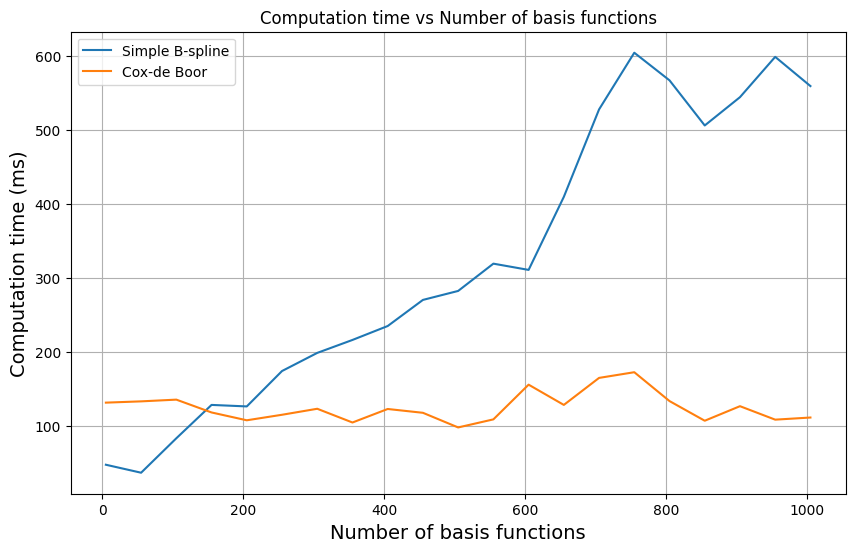

In [135]:
torch.manual_seed(42)

x = torch.linspace(0,0.99999,1000)

n_basis_span = []
t_simple = []
t_cox = []

for i in range(5,1006,50):
    degree, n_basis = 2, i
    n_basis_span.append(n_basis)

    nodal_values = torch.rand(n_basis)
    x_coords = torch.linspace(0.0, 1.0, len(nodal_values))
    control_points = torch.stack([x_coords, nodal_values], dim=1)

    model = bsplines(degree, n_basis, nodal_values)
    # Simple B_spline
    t0 = time.perf_counter()
    y_pred, y = model.forward(x)
    knot_points = model.knot_vector.detach().numpy()
    time_simple = time.perf_counter() - t0   
    t_simple.append(time_simple)


    # Implementation in Yau et al., CAD 38 (2006) 1123–1133
    t2 = time.perf_counter()
    y_cox = cox_de_boor_vector(x, control_points, model.knot_vector)
    time_cox = time.perf_counter() - t2
    t_cox.append(time_cox)

plt.figure(figsize=(10,6))
plt.plot(n_basis_span, np.array(t_simple)*1000, label='Simple B-spline')
plt.plot(n_basis_span, np.array(t_cox)*1000, label='Cox-de Boor')
plt.xlabel("Number of basis functions",fontsize=14)
plt.ylabel("Computation time (ms)",fontsize=14)
plt.title("Computation time vs Number of basis functions")
plt.legend()
plt.grid(True)
